# Vẽ ảnh hưởng của tốc độ học (mục 5.1.4): f(x) = x^2 + 5 sin(x), x0 = -5,

η = 0.01 (quá nhỏ), 0.1 (vừa phải), 0.5 (quá lớn)

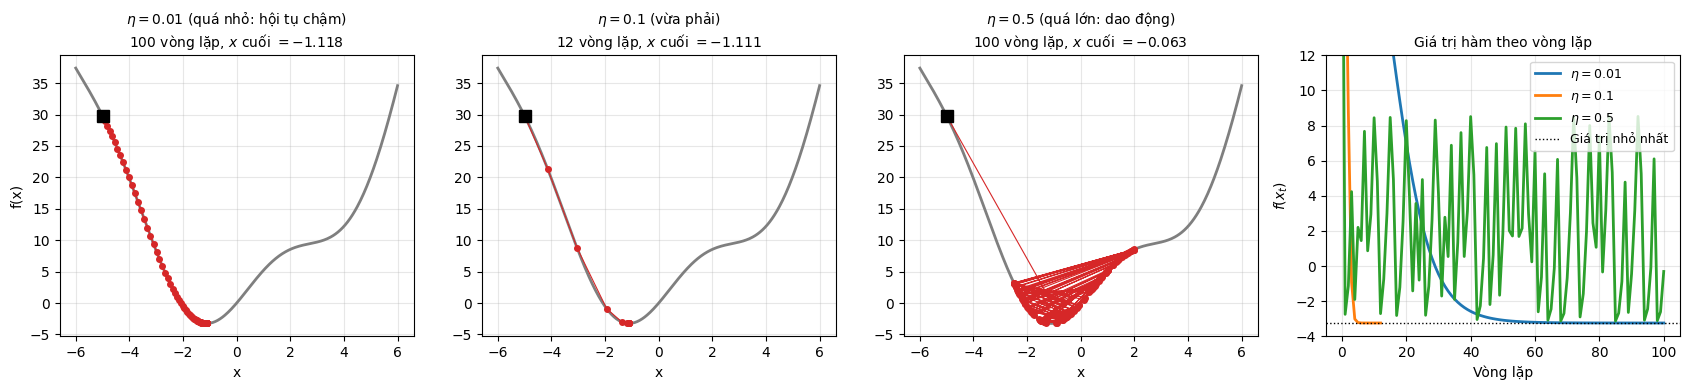

In [1]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

IMAGES = Path('.')   # thư mục images/ (notebook chạy trong images/)

def f(x):
    return x**2 + 5 * np.sin(x)

def grad(x):
    """Đạo hàm f'(x)."""
    return 2 * x + 5 * np.cos(x)

def gd(x0, eta, max_iter=100, tol=1e-3):
    """GD từ x0, dừng khi |f'(x)| < tol; trả về dãy x qua các vòng lặp."""
    x = x0
    history = [x0]
    for _ in range(max_iter):
        x = x - eta * grad(x)
        history.append(x)
        if abs(grad(x)) < tol:
            break
    return np.array(history)

x_line = np.linspace(-6, 6, 400)
# (tốc độ học η, nhận xét)
configs = [(0.01, "quá nhỏ: hội tụ chậm"), (0.1, "vừa phải"), (0.5, "quá lớn: dao động")]
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, (eta, label) in zip(axes[:3], configs):
    x_history = gd(-5, eta)
    ax.plot(x_line, f(x_line), color="#7F7F7F", lw=2)
    ax.plot(x_history, f(x_history), "o-", color="#D62728", ms=4, lw=0.8)
    ax.plot(x_history[0], f(x_history[0]), "s", color="black", ms=8)
    ax.set_title(f"$\\eta = {eta}$ ({label})\n{len(x_history) - 1} vòng lặp, $x$ cuối $= {x_history[-1]:.3f}$", fontsize=10)
    ax.set_xlabel("x"); ax.grid(alpha=0.3)
    axes[3].plot(f(x_history), lw=2, label=f"$\\eta = {eta}$")
axes[0].set_ylabel("f(x)")
axes[3].axhline(f(-1.1105), color="black", ls=":", lw=1, label="Giá trị nhỏ nhất")
axes[3].set_xlabel("Vòng lặp"); axes[3].set_ylabel("$f(x_t)$")
axes[3].set_title("Giá trị hàm theo vòng lặp", fontsize=10)
axes[3].set_ylim(-4, 12); axes[3].legend(fontsize=9); axes[3].grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES / "learning_rate.png", dpi=150)